In [1]:
import pandas as pd
#DATA UNDERSTANDING AND GRAPHS
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns


import pickle

# DATA PREPARATION
import nltk
from nltk.tokenize import word_tokenize
from nltk.tag import pos_tag
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re
import ast
from collections import Counter

from nltk.util import ngrams
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet


# OUR FUNCTIONS
from utils.visualizations import get_clean_words, extract_words
from langdetect import detect
from utils.functions_eda_preproc import verify_language, clean_text, normalize_text

import os
import pickle
import re
import nltk
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import plotly.express as px
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score
from tqdm import tqdm
from wordcloud import WordCloud
from mittens import GloVe
from gensim.models import Word2Vec
import utils.visualizations as visualizations
import importlib
importlib.reload(visualizations)
from utils.visualizations import word_cloud_generator, show_saved_images,cooccurrence_matrix_sentence_generator, plot_genre_cooccurrence, d2_embeddings_plotter

from sklearn.naive_bayes import ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import MultinomialNB
!pip install scikit-learn
from sklearn.naive_bayes import MultinomialNB


from utils.functions_vectors_modelling import evaluate_models, document_vector
import warnings
warnings.filterwarnings('ignore')

In [2]:
train = pd.read_csv('./Datasets/train.csv', index_col = 'id')
test = pd.read_csv('./Datasets/test.csv',index_col = 'id')
train.head()

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\r\nDid you mean it ...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\r\n[Hook]\r\nEverybody wants yo...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\r\nPeople tell me I've changed\r\nI ...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\r\nDon't try to ge...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\r\nI can see the end is coming but I...


In [3]:
train = train.rename(columns={'lyrics': 'raw_lyrics'})
test = test.rename(columns={'lyrics': 'raw_lyrics'})

In [4]:
train.drop_duplicates(subset=['raw_lyrics'], keep='first', inplace=True)

train.reset_index(drop=True, inplace=True)
print(f"Train dataset shape after removing duplicates: {train.shape}")

Train dataset shape after removing duplicates: (134789, 7)


In [5]:
train['lyrics_cleaned']= clean_text(train, 'raw_lyrics',
                                      emojis=True, hashtags=True, mentions=True,
                                      urls=True, html_tags=True, square_brackets=True,
                                      newlines=True, punctuation=True, apostrophes=True, whitespaces=True)

In [6]:
test['lyrics_cleaned']= clean_text(test, 'raw_lyrics',
                                      emojis=True, hashtags=True, mentions=True,
                                      urls=True, html_tags=True, square_brackets=True,
                                      newlines=True, punctuation=True, whitespaces=True)

In [8]:
custom_stopwords = ["chorus", "verse", "bridge", "intro", "outro", "hook", "solo", "get",
        "know", "go", "say", "make", "see", "come", "one", "like"]

train['lyrics_normalized'] = train['lyrics_cleaned'].apply(
    lambda x: normalize_text(
        x, 
        lemmatize= False,
        custom_stopwords= custom_stopwords,
        tokenized_output=False))

In [9]:
test['lyrics_normalized'] = test['lyrics_cleaned'].apply(
    lambda x: normalize_text(x,
        custom_stopwords= custom_stopwords,
        lemmatize = False,
        tokenized_output=False))

In [10]:
X = train["lyrics_normalized"].fillna("").astype(str)
y = train["tag"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training subset: {len(X_train):,} songs")
print(f"Validation subset: {len(X_val):,} songs")

Training subset: 107,831 songs
Validation subset: 26,958 songs


In [11]:
def evaluate_models(X_train_vec, X_test_vec, y_train, y_test, representation_name):
    models = {
        'Naive Bayes': MultinomialNB(),
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'SGD Classifier (SVM)': SGDClassifier(class_weight='balanced', loss='hinge', max_iter=1000, random_state=42),
        #'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=50, random_state=42, n_jobs=-1)
    }
    
    results = []
    
    for name, model in models.items():
        # Verifica valores negativos de forma segura tanto em matrizes esparsas (BoW/TF-IDF) como densas (Word2Vec/GloVe)
        has_negative = (X_train_vec < 0).nnz > 0 if hasattr(X_train_vec, "nnz") else (X_train_vec < 0).any()
        if name == 'Naive Bayes' and has_negative:
            print(f"A saltar {name} (não aceita valores negativos nas representações densas).")
            continue
            
        print(f"Training {name} with {representation_name}...")
        model.fit(X_train_vec, y_train)
        preds = model.predict(X_test_vec)
      
        score = f1_score(y_test, preds, average='macro')
        
        results.append({
            'Representation': representation_name,
            'Model': name,
            'Macro F1-Score': round(score, 4)
        })
        
    return pd.DataFrame(results).sort_values(by='Macro F1-Score', ascending=False)

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import RandomizedSearchCV, train_test_split

# Amostra estratificada de 40% para encontrar a melhor região rapidamente
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train, train_size=0.40, random_state=42, stratify=y_train
)

pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('classifier', SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42))
])

# Espaço alargado e justo para todas as famílias (incluindo max_features!)
param_distributions = [
    # 1. SGDClassifier (rápido e escalável)
    {
        'vectorizer': [TfidfVectorizer()],
        'vectorizer__max_features': [15000, 30000, 50000, None],
        'vectorizer__max_df': [0.65, 0.75, 0.85],
        'vectorizer__min_df': [2, 5, 10],
        'vectorizer__ngram_range': [(1, 2), (1, 3)],
        'vectorizer__sublinear_tf': [True, False],
        'classifier': [SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42)],
        'classifier__loss': ['log_loss', 'modified_huber', 'hinge'],
        'classifier__alpha': [0.00001, 0.00005, 0.0001]
    },
    # 2. Logistic Regression (com max_features controlado para não bloquear)
    {
        'vectorizer': [TfidfVectorizer()],
        'vectorizer__max_features': [15000, 30000, 50000],
        'vectorizer__max_df': [0.65, 0.75, 0.85],
        'vectorizer__min_df': [2, 5],
        'vectorizer__ngram_range': [(1, 2), (1, 3)],
        'vectorizer__sublinear_tf': [True, False],
        'classifier': [LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)],
        'classifier__C': [0.5, 1.0, 2.0, 5.0]
    },
    # 3. Naive Bayes (BoW e TF-IDF com alphas baixos para não sobre-suavizar TF-IDF)
    {
        'vectorizer': [CountVectorizer(), TfidfVectorizer()],
        'vectorizer__max_features': [15000, 30000, 50000, None],
        'vectorizer__max_df': [0.65, 0.75, 0.85],
        'vectorizer__min_df': [2, 5, 10],
        'vectorizer__ngram_range': [(1, 2), (1, 3)],
        'classifier': [MultinomialNB()],
        'classifier__alpha': [0.05, 0.1, 0.5, 1.0]
    }
]

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=45,            # Testa 35 combinações diversas em ~2-3 minutos
    scoring='f1_macro',
    cv=3,
    n_jobs=4,
    random_state=42,
    verbose=2
)

random_search.fit(X_train_sample, y_train_sample)

print("Melhor Macro F1-Score (CV):", round(random_search.best_score_, 4))
for param, value in random_search.best_params_.items():
    print(f"  {param}: {value}")

Fitting 3 folds for each of 45 candidates, totalling 135 fits
Melhor Macro F1-Score (CV): 0.5043
  vectorizer__sublinear_tf: True
  vectorizer__ngram_range: (1, 2)
  vectorizer__min_df: 5
  vectorizer__max_features: 50000
  vectorizer__max_df: 0.75
  vectorizer: TfidfVectorizer()
  classifier__loss: log_loss
  classifier__alpha: 5e-05
  classifier: SGDClassifier(class_weight='balanced', random_state=42)


In [13]:
import pandas as pd

cv_df = pd.DataFrame(random_search.cv_results_)
cv_df['Model'] = cv_df['param_classifier'].apply(lambda x: type(x).__name__)
cv_df['Representation'] = cv_df['param_vectorizer'].apply(lambda x: type(x).__name__)

# Tabela estilo mini-testes: melhor score de cada família (Modelo + Vetorizador)
resumo_modelos = (
    cv_df.sort_values('mean_test_score', ascending=False)
    .groupby(['Representation', 'Model'], as_index=False)
    .first()[['Representation', 'Model', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'params']]
    .rename(columns={
        'mean_test_score': 'Melhor Macro F1 (CV)',
        'std_test_score': 'Desvio Padrão',
        'mean_fit_time': 'Tempo Médio (s)'
    })
    .sort_values(by='Melhor Macro F1 (CV)', ascending=False)
    .reset_index(drop=True)
)

resumo_modelos['Melhor Macro F1 (CV)'] = resumo_modelos['Melhor Macro F1 (CV)'].round(4)
resumo_modelos['Desvio Padrão'] = resumo_modelos['Desvio Padrão'].round(4)
resumo_modelos['Tempo Médio (s)'] = resumo_modelos['Tempo Médio (s)'].round(2)

print("=== MELHOR RESULTADO POR MODELO E REPRESENTAÇÃO ===")
display(resumo_modelos)

print("\n=== TOP 10 COMBINAÇÕES TESTADAS ===")
top10 = cv_df.sort_values('mean_test_score', ascending=False)[
    ['Representation', 'Model', 'mean_test_score', 'mean_fit_time', 'params']
].head(10).reset_index(drop=True)
top10['mean_test_score'] = top10['mean_test_score'].round(4)
display(top10)

=== MELHOR RESULTADO POR MODELO E REPRESENTAÇÃO ===


,Representation,Model,Melhor Macro F1 (CV),Desvio Padrão,Tempo Médio (s),params
0,TfidfVectorizer,SGDClassifier,0.5043,0.0011,40.51,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
1,TfidfVectorizer,LogisticRegression,0.4741,0.0032,52.14,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
2,CountVectorizer,MultinomialNB,0.4614,0.0064,12.93,"{'vectorizer__ngram_range': (1, 2), 'vectorize..."
3,TfidfVectorizer,MultinomialNB,0.4235,0.0037,77.95,"{'vectorizer__ngram_range': (1, 3), 'vectorize..."



=== TOP 10 COMBINAÇÕES TESTADAS ===


,Representation,Model,mean_test_score,mean_fit_time,params
0,TfidfVectorizer,SGDClassifier,0.5043,40.510551,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
1,TfidfVectorizer,SGDClassifier,0.5013,79.973992,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
2,TfidfVectorizer,SGDClassifier,0.4996,26.820444,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
3,TfidfVectorizer,SGDClassifier,0.4886,23.085744,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
4,TfidfVectorizer,SGDClassifier,0.4834,26.883153,"{'vectorizer__sublinear_tf': False, 'vectorize..."
5,TfidfVectorizer,SGDClassifier,0.4801,40.590085,"{'vectorizer__sublinear_tf': False, 'vectorize..."
6,TfidfVectorizer,SGDClassifier,0.4787,27.269522,"{'vectorizer__sublinear_tf': False, 'vectorize..."
7,TfidfVectorizer,SGDClassifier,0.4772,24.702470,"{'vectorizer__sublinear_tf': False, 'vectorize..."
8,TfidfVectorizer,SGDClassifier,0.4748,80.849116,"{'vectorizer__sublinear_tf': False, 'vectorize..."
9,TfidfVectorizer,SGDClassifier,0.4744,17.096774,"{'vectorizer__sublinear_tf': True, 'vectorizer..."


In [14]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(sublinear_tf=True)),
    ('classifier', SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42))
])


param_grid = {
    'vectorizer__max_df': [0.68, 0.75, 0.78],
    'vectorizer__min_df': [4, 5, 6],
    'vectorizer__max_features': [40000, 50000, 60000],
    'vectorizer__ngram_range': [(1, 2)],
    'classifier__loss': ['log_loss', 'modified_huber'],
    'classifier__alpha': [0.00003, 0.00005, 0.00007]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=3  # 3 workers mantêm o PC rápido e a RAM segura
)

grid.fit(X_train_sample, y_train_sample)

print("Melhor Macro F1-Score (CV Fino):", round(grid.best_score_, 4))
for param, value in grid.best_params_.items():
    print(f"  {param}: {value}")

# Top 5 combinações da grelha fina para veres se houve diferença real
top5 = (
    pd.DataFrame(grid.cv_results_)
    .sort_values('mean_test_score', ascending=False)[['mean_test_score', 'std_test_score', 'params']]
    .head(5)
    .reset_index(drop=True)
)
top5['mean_test_score'] = top5['mean_test_score'].round(4)
top5['std_test_score'] = top5['std_test_score'].round(4)
display(top5)

Melhor Macro F1-Score (CV Fino): 0.5051
  classifier__alpha: 5e-05
  classifier__loss: log_loss
  vectorizer__max_df: 0.68
  vectorizer__max_features: 60000
  vectorizer__min_df: 4
  vectorizer__ngram_range: (1, 2)


,mean_test_score,std_test_score,params
0,0.5051,0.0016,"{'classifier__alpha': 5e-05, 'classifier__loss..."
1,0.5051,0.0016,"{'classifier__alpha': 5e-05, 'classifier__loss..."
2,0.5051,0.0016,"{'classifier__alpha': 5e-05, 'classifier__loss..."
3,0.5049,0.0008,"{'classifier__alpha': 5e-05, 'classifier__loss..."
4,0.5049,0.0008,"{'classifier__alpha': 5e-05, 'classifier__loss..."


In [15]:
import os
import pandas as pd
from sklearn.metrics import f1_score, classification_report


search_vencedor = grid
best_model = search_vencedor.best_estimator_

# 1. Treinar o modelo vencedor nos 100% do X_train e prever no X_val
best_model.fit(X_train, y_train)
val_preds = best_model.predict(X_val)

val_f1 = f1_score(y_val, val_preds, average='macro')
print(f" Global Macro F1-Score X_val (100% train): {val_f1:.4f}\n")

# 2. Tabela com o F1-Score de cada género
report = classification_report(y_val, val_preds, output_dict=True)
df_generos = pd.DataFrame([
    {"Genre": g, "F1-Score": round(report[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_generos)

# 3. Guardar no ficheiro CSV comparativo
linha = pd.DataFrame([{
    "Test": "duplicados_customstop_no_lemmatization",  # <-- muda este nome em cada experiência
    "Macro_F1": round(val_f1, 4),
    "country": round(report["country"]["f1-score"], 4),
    "rb": round(report["rb"]["f1-score"], 4),
    "pop": round(report["pop"]["f1-score"], 4),
    "rock": round(report["rock"]["f1-score"], 4),
    "misc": round(report["misc"]["f1-score"], 4),
    "rap": round(report["rap"]["f1-score"], 4),
    "Params": str(search_vencedor.best_params_)
}])

ficheiro_csv = "meus_resultados.csv"
linha.to_csv(ficheiro_csv, mode="a", header=not os.path.exists(ficheiro_csv), index=False)
display(pd.read_csv(ficheiro_csv).sort_values(by="Macro_F1", ascending=False))

 Global Macro F1-Score X_val (100% train): 0.5187



,Genre,F1-Score
0,rap,0.8531
1,pop,0.6522
2,misc,0.5649
3,rock,0.4127
4,country,0.3240
5,rb,0.3052


,Teste,Macro_F1,country,rb,pop,rock,misc,rap,Params
1,com_duplicados_e_custom_stopwords,0.5203,0.3211,0.3038,0.6530,0.4215,0.5669,0.8553,"{'classifier__alpha': 3e-05, 'classifier__loss..."
2,duplicados_customstop_no_lemmatization,0.5187,0.3240,0.3052,0.6522,0.4127,0.5649,0.8531,"{'classifier__alpha': 5e-05, 'classifier__loss..."
0,teste_só_remover_duplicados,0.5081,0.2873,0.2647,0.6555,0.4138,0.5845,0.8426,{'classifier': SGDClassifier(class_weight='bal...


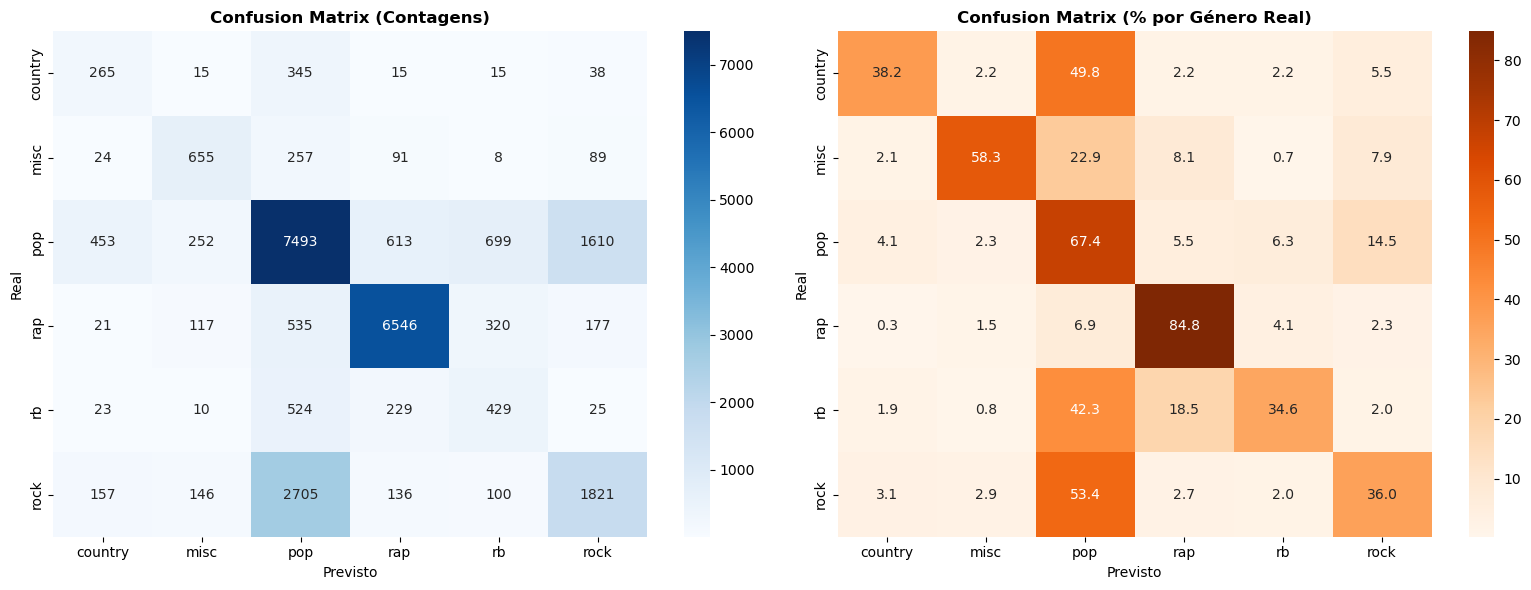

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = sorted(y_val.unique())
cm = confusion_matrix(y_val, val_preds, labels=labels)
cm_norm = confusion_matrix(y_val, val_preds, labels=labels, normalize='true') * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Contagens absolutas
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels, yticklabels=labels, ax=axes[0]
)
axes[0].set_title('Confusion Matrix (Contagens)', fontweight='bold')
axes[0].set_xlabel('Previsto')
axes[0].set_ylabel('Real')

# 2. Percentagem por género real (mais fácil de ver confusões em classes pequenas)
sns.heatmap(
    cm_norm, annot=True, fmt='.1f', cmap='Oranges',
    xticklabels=labels, yticklabels=labels, ax=axes[1]
)
axes[1].set_title('Confusion Matrix (% por Género Real)', fontweight='bold')
axes[1].set_xlabel('Previsto')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

In [18]:
import os
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, classification_report

# 1. Pesquisa rápida com LogisticRegression na amostra de treino
pipe_lr = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

param_dist_lr = {
    'vectorizer__max_features': [30000, 50000],
    'vectorizer__max_df': [0.75],
    'vectorizer__min_df': [3, 5],
    'vectorizer__ngram_range': [(1, 2)],
    'vectorizer__sublinear_tf': [True],
    'classifier__C': [0.5, 1.0, 2.0]
}

search_lr = RandomizedSearchCV(
    estimator=pipe_lr,
    param_distributions=param_dist_lr,
    n_iter=8,
    scoring='f1_macro',
    cv=3,
    n_jobs=3,
    random_state=42
)

search_lr.fit(X_train_sample, y_train_sample)
print("Melhor Macro F1-Score (CV LogisticRegression):", round(search_lr.best_score_, 4))
print("Melhores parâmetros:", search_lr.best_params_, "\n")

# 2. Treinar o vencedor nos 100% do X_train e avaliar no X_val
best_lr = search_lr.best_estimator_
best_lr.fit(X_train, y_train)
lr_preds = best_lr.predict(X_val)

lr_f1 = f1_score(y_val, lr_preds, average='macro')
print(f"Macro F1-Score Global no X_val (100% treino): {lr_f1:.4f}\n")

report_lr = classification_report(y_val, lr_preds, output_dict=True)
df_generos_lr = pd.DataFrame([
    {"Género": g, "F1-Score": round(report_lr[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_generos_lr)

# 3. Guardar no CSV comparativo
linha_lr = pd.DataFrame([{
    "Teste": "logisticreg_do_52.03",
    "Macro_F1": round(lr_f1, 4),
    "country": round(report_lr["country"]["f1-score"], 4),
    "rb": round(report_lr["rb"]["f1-score"], 4),
    "pop": round(report_lr["pop"]["f1-score"], 4),
    "rock": round(report_lr["rock"]["f1-score"], 4),
    "misc": round(report_lr["misc"]["f1-score"], 4),
    "rap": round(report_lr["rap"]["f1-score"], 4),
    "Params": str(search_lr.best_params_)
}])

ficheiro_csv = "meus_resultados.csv"
linha_lr.to_csv(ficheiro_csv, mode="a", header=not os.path.exists(ficheiro_csv), index=False)
display(pd.read_csv(ficheiro_csv).sort_values(by="Macro_F1", ascending=False))

Melhor Macro F1-Score (CV LogisticRegression): 0.4951
Melhores parâmetros: {'vectorizer__sublinear_tf': True, 'vectorizer__ngram_range': (1, 2), 'vectorizer__min_df': 3, 'vectorizer__max_features': 50000, 'vectorizer__max_df': 0.75, 'classifier__C': 2.0} 

Macro F1-Score Global no X_val (100% treino): 0.4969



,Género,F1-Score
0,rap,0.8502
1,misc,0.5451
2,pop,0.5418
3,rock,0.4641
4,country,0.2905
5,rb,0.2897


,Teste,Macro_F1,country,rb,pop,rock,misc,rap,Params
1,com_duplicados_e_custom_stopwords,0.5203,0.3211,0.3038,0.6530,0.4215,0.5669,0.8553,"{'classifier__alpha': 3e-05, 'classifier__loss..."
2,duplicados_customstop_no_lemmatization,0.5187,0.3240,0.3052,0.6522,0.4127,0.5649,0.8531,"{'classifier__alpha': 5e-05, 'classifier__loss..."
0,teste_só_remover_duplicados,0.5081,0.2873,0.2647,0.6555,0.4138,0.5845,0.8426,{'classifier': SGDClassifier(class_weight='bal...
3,logisticreg_do_52.03,0.4969,0.2905,0.2897,0.5418,0.4641,0.5451,0.8502,"{'vectorizer__sublinear_tf': True, 'vectorizer..."


In [20]:
import numpy as np
import pandas as pd

# Usa 'best_lr' se acabaste de correr a célula 2; troca para 'best_model' se quiseres inspecionar o teu modelo anterior
modelo_inspecao = best_model

vectorizer = modelo_inspecao.named_steps['vectorizer']
classifier = modelo_inspecao.named_steps['classifier']

feature_names = np.array(vectorizer.get_feature_names_out())
classes = list(classifier.classes_)

def top_features_para_classe(genre, n=20):
    idx = classes.index(genre)
    pesos = classifier.coef_[idx]
    
    top_pos_idx = np.argsort(pesos)[-n:][::-1]
    top_neg_idx = np.argsort(pesos)[:n]
    
    df_pos = pd.DataFrame({
        f"Mais puxa para {genre}": feature_names[top_pos_idx],
        "Peso (+)": np.round(pesos[top_pos_idx], 4)
    })
    df_neg = pd.DataFrame({
        f"Mais afasta de {genre}": feature_names[top_neg_idx],
        "Peso (-)": np.round(pesos[top_neg_idx], 4)
    })
    return pd.concat([df_pos, df_neg], axis=1)

print("=== POP ===")
display(top_features_para_classe("pop", n=15))

print("=== COUNTRY ===")
display(top_features_para_classe("country", n=15))

print("=== RB ===")
display(top_features_para_classe("rb", n=15))

=== POP ===


,Mais puxa para pop,Peso (+),Mais afasta de pop,Peso (-)
0,oh,2.0590,shit,-4.1180
1,love,1.4404,fuck,-3.7262
2,theres,1.3848,bitch,-3.3929
3,heart,1.1888,nigga,-3.2185
4,sing,0.9068,niggas,-3.0036
5,dance,0.9041,fucking,-2.7777
6,hes,0.9020,tryna,-2.7169
7,dancing,0.8932,gon,-2.4107
8,could,0.8868,em,-2.1196
9,tonight,0.8692,yeah,-2.0662


=== COUNTRY ===


,Mais puxa para country,Peso (+),Mais afasta de country,Peso (-)
0,old,5.0465,fuck,-4.2610
1,town,3.8415,shit,-3.9877
2,little,3.5301,feel,-3.2168
3,country,3.5216,bitch,-3.0534
4,love,3.5097,fucking,-2.7925
5,well,3.2620,nigga,-2.7818
6,whiskey,3.1992,want,-2.5769
7,truck,3.1165,niggas,-2.4215
8,long,2.7938,yo,-2.3868
9,lord,2.7105,life,-2.2740


=== RB ===


,Mais puxa para rb,Peso (+),Mais afasta de rb,Peso (-)
0,baby,6.2009,bitch,-3.3855
1,girl,4.8618,well,-2.9088
2,yeah,3.9860,niggas,-1.9977
3,ooh,3.8536,kill,-1.8304
4,love,3.8237,blood,-1.7015
5,want,3.3117,old,-1.5708
6,babe,3.1618,rap,-1.5117
7,oh,3.0995,fear,-1.5031
8,gon,2.8510,rock,-1.4807
9,feelings,2.7452,boys,-1.4720


In [21]:
import os
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, classification_report

# Dicionário de pesos ajustado sobre o 'balanced' para travar o efeito "aspirador" do pop
# (O scikit-learn multiplica estes fatores pelos pesos automáticos do 'balanced')
pesos_custom = {
    'country': 1.25,
    'rb': 1.25,
    'rock': 1.15,
    'pop': 0.85,
    'misc': 1.0,
    'rap': 1.0
}

# Usa exatamente os melhores parâmetros que já ganhaste no SGDClassifier
modelo_pesos = Pipeline([
    ('vectorizer', TfidfVectorizer(
        max_df=0.7,
        min_df=5,
        max_features=75000,
        ngram_range=(1, 2),
        sublinear_tf=True
        # Se ainda quiseres tirar a teima das palavras comuns em 30s, descomenta a linha abaixo:
        # stop_words=['love', 'oh', 'yeah', 'heart']
    )),
    ('classifier', SGDClassifier(
        loss='log_loss',
        alpha=3e-05,          # <-- confirma se no teu 0.5203 foi 3e-05 ou 5e-05
        class_weight=pesos_custom,
        max_iter=1000,
        random_state=42
    ))
])

modelo_pesos.fit(X_train, y_train)
preds_pesos = modelo_pesos.predict(X_val)

f1_pesos = f1_score(y_val, preds_pesos, average='macro')
print(f"Macro F1-Score Global (com ajuste de pesos): {f1_pesos:.4f}\n")

report_p = classification_report(y_val, preds_pesos, output_dict=True)
df_p = pd.DataFrame([
    {"Género": g, "F1-Score": round(report_p[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_p)

# Guardar no CSV
linha_p = pd.DataFrame([{
    "Teste": "sgd_class_weight_ajustado",
    "Macro_F1": round(f1_pesos, 4),
    "country": round(report_p["country"]["f1-score"], 4),
    "rb": round(report_p["rb"]["f1-score"], 4),
    "pop": round(report_p["pop"]["f1-score"], 4),
    "rock": round(report_p["rock"]["f1-score"], 4),
    "misc": round(report_p["misc"]["f1-score"], 4),
    "rap": round(report_p["rap"]["f1-score"], 4),
    "Params": str(pesos_custom)
}])

ficheiro_csv = "meus_resultados.csv"
linha_p.to_csv(ficheiro_csv, mode="a", header=not os.path.exists(ficheiro_csv), index=False)
display(pd.read_csv(ficheiro_csv).sort_values(by="Macro_F1", ascending=False))

Macro F1-Score Global (com ajuste de pesos): 0.4104



,Género,F1-Score
0,rap,0.8583
1,pop,0.7027
2,misc,0.4968
3,rock,0.3342
4,rb,0.0592
5,country,0.0114


,Teste,Macro_F1,country,rb,pop,rock,misc,rap,Params
1,com_duplicados_e_custom_stopwords,0.5203,0.3211,0.3038,0.6530,0.4215,0.5669,0.8553,"{'classifier__alpha': 3e-05, 'classifier__loss..."
2,duplicados_customstop_no_lemmatization,0.5187,0.3240,0.3052,0.6522,0.4127,0.5649,0.8531,"{'classifier__alpha': 5e-05, 'classifier__loss..."
0,teste_só_remover_duplicados,0.5081,0.2873,0.2647,0.6555,0.4138,0.5845,0.8426,{'classifier': SGDClassifier(class_weight='bal...
3,logisticreg_do_52.03,0.4969,0.2905,0.2897,0.5418,0.4641,0.5451,0.8502,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
4,sgd_class_weight_ajustado,0.4104,0.0114,0.0592,0.7027,0.3342,0.4968,0.8583,"{'country': 1.25, 'rb': 1.25, 'rock': 1.15, 'p..."


In [22]:
import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, classification_report

# 1. Calcular os pesos exatos que o 'balanced' usa no teu X_train
classes = np.unique(y_train)
pesos_base = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
pesos_balanced = dict(zip(classes, pesos_base))

# 2. Multiplicar ESSES pesos reais pelos fatores de ajuste
ajustes = {
    'country': 1.20,
    'rb': 1.20,
    'rock': 1.10,
    'pop': 0.90,
    'misc': 1.0,
    'rap': 1.0
}
pesos_reais = {c: pesos_balanced[c] * ajustes[c] for c in classes}
print("Pesos reais aplicados:", {k: round(v, 2) for k, v in pesos_reais.items()}, "\n")

# 3. Treinar e avaliar
modelo_pesos = Pipeline([
    ('vectorizer', TfidfVectorizer(
        max_df=0.7,
        min_df=5,
        max_features=75000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ('classifier', SGDClassifier(
        loss='log_loss',
        alpha=3e-05,
        class_weight=pesos_reais,
        max_iter=1000,
        random_state=42
    ))
])

modelo_pesos.fit(X_train, y_train)
preds_pesos = modelo_pesos.predict(X_val)

f1_pesos = f1_score(y_val, preds_pesos, average='macro')
print(f"Macro F1-Score Global (pesos reais ajustados): {f1_pesos:.4f}\n")

report_p = classification_report(y_val, preds_pesos, output_dict=True)
df_p = pd.DataFrame([
    {"Género": g, "F1-Score": round(report_p[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_p)

Pesos reais aplicados: {'country': np.float64(7.79), 'misc': np.float64(4.0), 'pop': np.float64(0.36), 'rap': np.float64(0.58), 'rb': np.float64(4.35), 'rock': np.float64(0.98)} 

Macro F1-Score Global (pesos reais ajustados): 0.5154



,Género,F1-Score
0,rap,0.8544
1,pop,0.6046
2,misc,0.5619
3,rock,0.4473
4,country,0.3203
5,rb,0.3035


In [23]:
import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, classification_report

# 1. Calcular os pesos exatos que o 'balanced' usa no teu X_train
classes = np.unique(y_train)
pesos_base = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
pesos_balanced = dict(zip(classes, pesos_base))

# 2. Multiplicar ESSES pesos reais pelos fatores de ajuste
ajustes = {
    'country': 1.20,
    'rb': 1.20,
    'rock': 1.10,
    'pop': 0.90,
    'misc': 1.0,
    'rap': 1.0
}
pesos_reais = {c: pesos_balanced[c] * ajustes[c] for c in classes}
print("Pesos reais aplicados:", {k: round(v, 2) for k, v in pesos_reais.items()}, "\n")

# 3. Treinar e avaliar
modelo_pesos = Pipeline([
    ('vectorizer', TfidfVectorizer(
        max_df=0.7,
        min_df=5,
        max_features=75000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        stop_words=['love', 'oh', 'yeah', 'heart']
    )),
    ('classifier', SGDClassifier(
        loss='log_loss',
        alpha=3e-05,
        class_weight=pesos_reais,
        max_iter=1000,
        random_state=42
    ))
])

modelo_pesos.fit(X_train, y_train)
preds_pesos = modelo_pesos.predict(X_val)

f1_pesos = f1_score(y_val, preds_pesos, average='macro')
print(f"Macro F1-Score Global (pesos reais ajustados): {f1_pesos:.4f}\n")

report_p = classification_report(y_val, preds_pesos, output_dict=True)
df_p = pd.DataFrame([
    {"Género": g, "F1-Score": round(report_p[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_p)

Pesos reais aplicados: {'country': np.float64(7.79), 'misc': np.float64(4.0), 'pop': np.float64(0.36), 'rap': np.float64(0.58), 'rb': np.float64(4.35), 'rock': np.float64(0.98)} 

Macro F1-Score Global (pesos reais ajustados): 0.5112



,Género,F1-Score
0,rap,0.8533
1,pop,0.6035
2,misc,0.5579
3,rock,0.4478
4,country,0.3082
5,rb,0.2968


In [24]:
import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, classification_report


# 2.


# 3. Treinar e avaliar
modelo_pesos = Pipeline([
    ('vectorizer', TfidfVectorizer(
        max_df=0.7,
        min_df=5,
        max_features=75000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        stop_words=['love', 'oh', 'yeah', 'heart']
    )),
    ('classifier', SGDClassifier(
        loss='log_loss',
        alpha=3e-05,
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

modelo_pesos.fit(X_train, y_train)
preds_pesos = modelo_pesos.predict(X_val)

f1_pesos = f1_score(y_val, preds_pesos, average='macro')
print(f"Macro F1-Score Global (pesos reais ajustados): {f1_pesos:.4f}\n")

report_p = classification_report(y_val, preds_pesos, output_dict=True)
df_p = pd.DataFrame([
    {"Género": g, "F1-Score": round(report_p[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_p)

linha_p = pd.DataFrame([{
    "Teste": "sgd_class_weight_ajustado",
    "Macro_F1": round(f1_pesos, 4),
    "country": round(report_p["country"]["f1-score"], 4),
    "rb": round(report_p["rb"]["f1-score"], 4),
    "pop": round(report_p["pop"]["f1-score"], 4),
    "rock": round(report_p["rock"]["f1-score"], 4),
    "misc": round(report_p["misc"]["f1-score"], 4),
    "rap": round(report_p["rap"]["f1-score"], 4),
    "Params": str(pesos_custom)
}])

ficheiro_csv = "meus_resultados.csv"
linha_p.to_csv(ficheiro_csv, mode="a", header=not os.path.exists(ficheiro_csv), index=False)
display(pd.read_csv(ficheiro_csv).sort_values(by="Macro_F1", ascending=False))

Macro F1-Score Global (pesos reais ajustados): 0.5172



,Género,F1-Score
0,rap,0.8542
1,pop,0.6538
2,misc,0.5677
3,rock,0.4163
4,country,0.3133
5,rb,0.2979


,Teste,Macro_F1,country,rb,pop,rock,misc,rap,Params
1,com_duplicados_e_custom_stopwords,0.5203,0.3211,0.3038,0.6530,0.4215,0.5669,0.8553,"{'classifier__alpha': 3e-05, 'classifier__loss..."
2,duplicados_customstop_no_lemmatization,0.5187,0.3240,0.3052,0.6522,0.4127,0.5649,0.8531,"{'classifier__alpha': 5e-05, 'classifier__loss..."
5,sgd_class_weight_ajustado,0.5172,0.3133,0.2979,0.6538,0.4163,0.5677,0.8542,"{'country': 1.25, 'rb': 1.25, 'rock': 1.15, 'p..."
0,teste_só_remover_duplicados,0.5081,0.2873,0.2647,0.6555,0.4138,0.5845,0.8426,{'classifier': SGDClassifier(class_weight='bal...
3,logisticreg_do_52.03,0.4969,0.2905,0.2897,0.5418,0.4641,0.5451,0.8502,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
4,sgd_class_weight_ajustado,0.4104,0.0114,0.0592,0.7027,0.3342,0.4968,0.8583,"{'country': 1.25, 'rb': 1.25, 'rock': 1.15, 'p..."


In [26]:
import os
import pandas as pd
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, classification_report

# 1. Confirmar os parâmetros exatos do teu recorde de 0.5203 guardados no CSV
df_res = pd.read_csv("meus_resultados.csv")
melhor_linha = df_res.sort_values(by="Macro_F1", ascending=False).iloc[0]
print("Parâmetros exatos do 0.5203:", melhor_linha["Params"], "\n")

# 2. Combinar TF-IDF de palavras (1,2) + caracteres (3,5) sobre o X_train já em memória
modelo_union = Pipeline([
    ('features', FeatureUnion([
        ('word', TfidfVectorizer(
            max_df=0.7,
            min_df=5,
            max_features=75000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ('char', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(3, 5),
            min_df=5,
            max_features=75000,
            sublinear_tf=True
        ))
    ])),
    ('classifier', SGDClassifier(
        loss='log_loss',
        alpha=3e-05,
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

modelo_union.fit(X_train, y_train)
preds_union = modelo_union.predict(X_val)

f1_union = f1_score(y_val, preds_union, average='macro')
print(f"Macro F1-Score Global (Word + Char_wb): {f1_union:.4f}\n")

# 3. Ver F1 por género
report_u = classification_report(y_val, preds_union, output_dict=True)
df_u = pd.DataFrame([
    {"Género": g, "F1-Score": round(report_u[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_u)

# 4. Guardar no CSV para comparar lado a lado com o 0.5203
linha_u = pd.DataFrame([{
    "Teste": "sgd_word_plus_char_wb",
    "Macro_F1": round(f1_union, 4),
    "country": round(report_u["country"]["f1-score"], 4),
    "rb": round(report_u["rb"]["f1-score"], 4),
    "pop": round(report_u["pop"]["f1-score"], 4),
    "rock": round(report_u["rock"]["f1-score"], 4),
    "misc": round(report_u["misc"]["f1-score"], 4),
    "rap": round(report_u["rap"]["f1-score"], 4),
    "Params": "FeatureUnion(word(1,2,40k) + char_wb(3,5,50k)), alpha=3e-05, balanced"
}])

ficheiro_csv = "meus_resultados.csv"
linha_u.to_csv(ficheiro_csv, mode="a", header=not os.path.exists(ficheiro_csv), index=False)
display(pd.read_csv(ficheiro_csv).sort_values(by="Macro_F1", ascending=False))

Parâmetros exatos do 0.5203: FeatureUnion(word(1,2,40k) + char_wb(3,5,50k)), alpha=3e-05, balanced 

Macro F1-Score Global (Word + Char_wb): 0.5222



,Género,F1-Score
0,rap,0.8620
1,pop,0.6423
2,misc,0.5753
3,rock,0.4333
4,country,0.3200
5,rb,0.3006


,Teste,Macro_F1,country,rb,pop,rock,misc,rap,Params
7,sgd_word_plus_char_wb,0.5222,0.3200,0.3006,0.6423,0.4333,0.5753,0.8620,"FeatureUnion(word(1,2,40k) + char_wb(3,5,50k))..."
6,sgd_word_plus_char_wb,0.5210,0.3187,0.3022,0.6379,0.4363,0.5695,0.8617,"FeatureUnion(word(1,2,40k) + char_wb(3,5,50k))..."
1,com_duplicados_e_custom_stopwords,0.5203,0.3211,0.3038,0.6530,0.4215,0.5669,0.8553,"{'classifier__alpha': 3e-05, 'classifier__loss..."
2,duplicados_customstop_no_lemmatization,0.5187,0.3240,0.3052,0.6522,0.4127,0.5649,0.8531,"{'classifier__alpha': 5e-05, 'classifier__loss..."
5,sgd_class_weight_ajustado,0.5172,0.3133,0.2979,0.6538,0.4163,0.5677,0.8542,"{'country': 1.25, 'rb': 1.25, 'rock': 1.15, 'p..."
0,teste_só_remover_duplicados,0.5081,0.2873,0.2647,0.6555,0.4138,0.5845,0.8426,{'classifier': SGDClassifier(class_weight='bal...
3,logisticreg_do_52.03,0.4969,0.2905,0.2897,0.5418,0.4641,0.5451,0.8502,"{'vectorizer__sublinear_tf': True, 'vectorizer..."
4,sgd_class_weight_ajustado,0.4104,0.0114,0.0592,0.7027,0.3342,0.4968,0.8583,"{'country': 1.25, 'rb': 1.25, 'rock': 1.15, 'p..."
